# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [10]:
# data=pd.read_csv("SiComplete-2021-12-19-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2022-08-22-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2022-11-01-BiatriSrv-v2.3-WithToleranceOnField-WithAll.csv", "\t", header=2)
data.describe(include="all")
data=data.rename(columns={"##JobID": "JobID"})
data=data.convert_dtypes()
print(data.dtypes)
datafull=data

JobID                             Int64
RunDate                           Int64
kgrid                             Int64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                           Int64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                           Int64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                       Int64
InducedFields                     Int64
ProbeFieldAmplitude_AU            Int64
ProbeFieldDelay_s               float64
Functional                        Int64
FrozenHxc                         Int64
MoveIon                           Int64
NeMax                           float64
NeFinal                         float64


# Database filtering

In [11]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=24]
data

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615,20180508,24,0.434637,0.25,8.000000e-07,2.000000e-14,800000000,0.000000,0.0,...,0.006785,0.003398,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3,2,2262.5,937.147441
1,5882467,20180909,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.010887,0.004497,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3,2,3087.5,1350.561171
2,5882393,20180904,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.012325,-0.076743,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3,2,3175.0,1350.561171
3,5882390,20180904,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.006391,-0.037511,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3,2,3262.5,1350.561171
4,5882469,20180909,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.014642,0.006659,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3,2,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2786,245620,20221024,24,0.434637,0.20,1.062500e-06,4.980469e-14,6070000000,0.157080,0.0,...,1.075489,0.087372,4.431748e+15,4.612854e+28,9.259699e+41,9.261888e+41,1,0,4400.0,4117.988325
2787,249930,20221030,24,0.434637,0.25,1.062500e-06,4.980469e-14,1000000000,0.157080,0.0,...,0.001522,0.000003,-2.194236e+14,6.596159e+25,1.313132e+39,1.324405e+39,1,0,5290.0,4117.988325
2788,243837,20221008,24,0.434637,0.25,1.062500e-06,4.980469e-14,6070000000,0.314159,0.0,...,1.085488,-0.041180,3.934642e+15,4.665260e+28,9.365146e+41,9.367110e+41,1,0,5290.0,4117.988325
2789,249931,20221030,24,0.434637,0.25,1.062500e-06,4.980469e-14,1000000000,0.314159,0.0,...,0.001711,0.000002,-2.107720e+14,7.483224e+25,1.490696e+39,1.502514e+39,1,0,5290.0,4117.988325


In [12]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615,20180508,24,0.434637,0.25,8.000000e-07,2.000000e-14,800000000,0.000000,0.0,...,0.006785,0.003398,-2.567968e+13,2.810224e+26,1.404822e+40,1.405112e+40,3,2,2262.5,937.147441
1,5882467,20180909,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.010887,0.004497,-3.133202e+14,4.732762e+26,1.570724e+40,1.577587e+40,3,2,3087.5,1350.561171
2,5882393,20180904,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.012325,-0.076743,-1.059137e+14,4.437532e+26,1.477840e+40,1.479177e+40,3,2,3175.0,1350.561171
3,5882390,20180904,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.006391,-0.037511,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3,2,3262.5,1350.561171
4,5882469,20180909,24,0.434637,0.25,8.000000e-07,3.000000e-14,700000000,0.000000,0.0,...,0.014642,0.006659,-3.211845e+14,6.640696e+26,2.200183e+40,2.213565e+40,3,2,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2786,245620,20221024,24,0.434637,0.20,1.062500e-06,4.980469e-14,6070000000,0.157080,0.0,...,1.075489,0.087372,4.431748e+15,4.612854e+28,9.259699e+41,9.261888e+41,1,0,4400.0,4117.988325
2787,249930,20221030,24,0.434637,0.25,1.062500e-06,4.980469e-14,1000000000,0.157080,0.0,...,0.001522,0.000003,-2.194236e+14,6.596159e+25,1.313132e+39,1.324405e+39,1,0,5290.0,4117.988325
2788,243837,20221008,24,0.434637,0.25,1.062500e-06,4.980469e-14,6070000000,0.314159,0.0,...,1.085488,-0.041180,3.934642e+15,4.665260e+28,9.365146e+41,9.367110e+41,1,0,5290.0,4117.988325
2789,249931,20221030,24,0.434637,0.25,1.062500e-06,4.980469e-14,1000000000,0.314159,0.0,...,0.001711,0.000002,-2.107720e+14,7.483224e+25,1.490696e+39,1.502514e+39,1,0,5290.0,4117.988325


In [13]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [14]:
datafull

,JobID,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,CEP1,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637,20180601,24,0.434637,0.25,2.000000e-07,2.000000e-14,100000000,0.0,0.0,...,8.262708e-04,0.000004,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3,2,3812.5,854.407455
1468,8715191,20190625,24,0.434637,0.25,2.000000e-07,2.000000e-14,500000000,0.0,0.0,...,1.952543e-02,-0.000109,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3,2,3125.0,854.407455
1523,8918119,20190708,24,0.434637,0.25,2.000000e-07,2.000000e-14,750000000,0.0,0.0,...,4.079272e-02,-0.000297,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3,2,3125.0,854.407455
312,5027620,20180524,24,0.434637,0.25,2.000000e-07,2.000000e-14,1000000000,0.0,0.0,...,6.555565e-02,0.000637,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3,2,2975.0,854.407455
1413,8918121,20190709,24,0.434637,0.25,2.000000e-07,2.000000e-14,1500000000,0.0,0.0,...,1.123667e-01,-0.001849,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3,2,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1403,10050046,20191101,24,0.434637,0.25,4.100000e-06,2.000000e-14,500000000,0.0,0.0,...,3.690789e-07,0.000226,4.772547e+13,3.844612e+27,2.465914e+35,1.922306e+41,3,2,3750.0,1392.217365
1738,17608855,20200127,24,0.434637,0.25,6.400000e-06,6.000000e-14,500000000,0.0,0.0,...,2.562692e-06,0.000335,9.126526e+13,5.590327e+24,7.342516e+34,9.317212e+37,3,2,7750.0,3363.042231
1735,17638129,20200127,24,0.434637,0.25,6.400000e-06,6.000000e-14,750000000,0.0,0.0,...,2.733345e-05,0.000839,7.494762e+13,1.337371e+25,1.286704e+37,2.228952e+38,3,2,7625.0,3363.042231
1711,17608858,20200127,24,0.434637,0.25,6.400000e-06,6.000000e-14,1000000000,0.0,0.0,...,4.830202e-04,0.001603,-5.717359e+12,3.822728e+25,2.664830e+38,6.371213e+38,3,2,7500.0,3363.042231


In [15]:
set(datafull[datafull.PolarizationAngle!=0].lambda1)

{1.0625e-06, 2.656e-06}

In [9]:
from octopus_slabs.Libs.libPlotting import PulseTypeID
print(PulseTypeID['SinSquared'])
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda1-800e-9)<1e-9]
datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['SinSquared']]
# datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

1


In [20]:
datatmp.to_csv('Si-k40-Nexc-Orientation.csv')

In [10]:
!pwd
datatmp.tau1

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


2593    1.394500e-14
2591    1.394500e-14
2586    1.394500e-14
2584    1.394500e-14
2754    1.394500e-14
2758    1.394500e-14
2751    1.394500e-14
2755    1.394500e-14
2752    1.394500e-14
2587    1.394500e-14
2756    1.394500e-14
2585    1.394500e-14
2750    1.394500e-14
2753    1.394500e-14
2757    1.394500e-14
2583    1.394500e-14
2685    1.394500e-14
2682    1.394500e-14
Name: tau1, dtype: float64

In [11]:
from scipy.constants import e, epsilon_0, c
0.5*c*epsilon_0*datatmp.Efield1**2/1E4

2593    1.194488e+12
2591    1.194488e+12
2586    1.194488e+12
2584    1.194488e+12
2754    1.194488e+12
2758    1.194488e+12
2751    1.194488e+12
2755    1.194488e+12
2752    1.194488e+12
2587    1.194488e+12
2756    1.194488e+12
2585    1.194488e+12
2750    1.194488e+12
2753    1.194488e+12
2757    1.194488e+12
2583    1.194488e+12
2685    1.194488e+12
2682    1.194488e+12
Name: Efield1, dtype: float64

In [18]:
print(datatmp.STH)
print(datatmp.RiseCycles)
print(datatmp.Efield1)

2501    1
2499    1
2494    1
2492    1
2588    1
2592    1
2585    1
2589    1
2586    1
2495    1
2590    1
2493    1
2584    1
2587    1
2591    1
2491    1
2543    1
2540    1
Name: STH, dtype: Int64
2501    0
2499    0
2494    0
2492    0
2588    0
2592    0
2585    0
2589    0
2586    0
2495    0
2590    0
2493    0
2584    0
2587    0
2591    0
2491    0
2543    0
2540    0
Name: RiseCycles, dtype: Int64
2501    3000000000
2499    3000000000
2494    3000000000
2492    3000000000
2588    3000000000
2592    3000000000
2585    3000000000
2589    3000000000
2586    3000000000
2495    3000000000
2590    3000000000
2493    3000000000
2584    3000000000
2587    3000000000
2591    3000000000
2491    3000000000
2543    3000000000
2540    3000000000
Name: Efield1, dtype: Int64


In [14]:
datatmp.PolarizationAngle/np.pi

2501    0.00
2499    0.00
2494    0.02
2492    0.04
2588    0.05
2592    0.06
2585    0.08
2589    0.10
2586    0.12
2495    0.14
2590    0.15
2493    0.16
2584    0.18
2587    0.20
2591    0.22
2491    0.24
2543    0.25
2540    0.25
Name: PolarizationAngle, dtype: float64

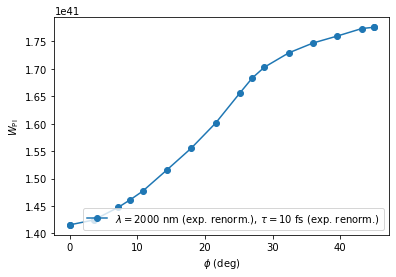

In [12]:
from scipy.constants import pi
plt.figure()
plt.subplot(polar=False)
plt.plot(180./pi*data2.PolarizationAngle, data2.Wpi_afterpulse, "-o", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()

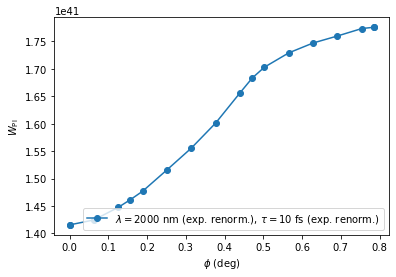

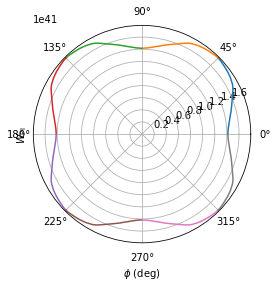

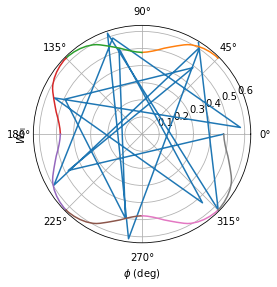

In [16]:
plt.figure()
plt.subplot(polar=False)
plt.plot(data2.PolarizationAngle, data2.Wpi_afterpulse, "-o", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend(loc="best")
plt.show()


plt.figure()
plt.subplot(polar=True)
plt.plot(data2.PolarizationAngle, data2.Wpi_afterpulse, "-", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+2*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(4*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+4*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(6*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")
plt.plot(data2.PolarizationAngle+6*45./180.*np.pi, data2.Wpi_afterpulse, "-")
plt.plot(8*45./180.*np.pi-data2.PolarizationAngle, data2.Wpi_afterpulse, "-")

# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.legend(loc="best")
plt.show()

plt.figure()
plt.subplot(polar=True)
plt.plot(data2.PolarizationAngle*180./pi, data2.Energy_afterpulse_eV, "-", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
plt.plot(2*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+2*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(4*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+4*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(6*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")
plt.plot(data2.PolarizationAngle+6*45./180.*np.pi, data2.Energy_afterpulse_eV, "-")
plt.plot(8*45./180.*np.pi-data2.PolarizationAngle, data2.Energy_afterpulse_eV, "-")

# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
# plt.legend(loc="best")
plt.show()

Now that data is available, let's try to build up an angle-dependent plot, like in Tancogne-Dejean et al., Physical review letters, 2016, 118, 087403. 

In [17]:
"""import glob
for JobID_id in datatmp.JobID:
    print(("JobID: "+str(JobID_id)))
    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"
    # print(FileLookUp)
    ListFound = glob.glob("*/*/*/" + FileLookUp)
    # print(ListFound)
    entry=datatmp[datatmp.JobID==JobID_id]
    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double
    print(PolarizationAngle * 180. / np.pi)
    """

'import glob\nfor JobID_id in datatmp.JobID:\n    print(("JobID: "+str(JobID_id)))\n    FileLookUp = "octopus-td." + str(JobID_id) + "*.log"\n    # print(FileLookUp)\n    ListFound = glob.glob("*/*/*/" + FileLookUp)\n    # print(ListFound)\n    entry=datatmp[datatmp.JobID==JobID_id]\n    PolarizationAngle = np.array(entry.PolarizationAngle)[0] #reduces the content from DataFrame to Double\n    print(PolarizationAngle * 180. / np.pi)\n    '